# When should mosquito control start? A dengue SIR model for Colombo, calibrated with MCMC

[One-paragraph summary, written last: the problem, the model, the key result and how it was verified.]

In [5]:
# Setup: imports, random seed and data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                      # every random result in this notebook uses this seed
rng = np.random.default_rng(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__)

# Use the local copy when the repository is cloned; download it on a fresh Colab runtime.
DATA_URL = "https://raw.githubusercontent.com/geethsenaviratne/dengue-sir-mcmc-colombo/main/data/colombo_2017.csv"
try:
    cases = pd.read_csv("../data/colombo_2017.csv")
except FileNotFoundError:
    cases = pd.read_csv(DATA_URL)

assert len(cases) == 52 and cases["week"].tolist() == list(range(1, 53)), "expected 52 consecutive weeks of 2017"
cases.head()

numpy 2.5.5 | pandas 3.1.1


,year,week,start_date,end_date,cases
0,2017,1,2016-12-31,2017-01-06,342
1,2017,2,2017-01-07,2017-01-13,531
2,2017,3,2017-01-14,2017-01-20,565
3,2017,4,2017-01-21,2017-01-27,482
4,2017,5,2017-01-28,2017-02-03,417


## 1. Problem and question

In 2017, Colombo district had its largest dengue epidemic in the weekly records that begin in 2007. Reported cases rose from a few hundred a week early in the year to 1,972 in the week beginning 15 July, then collapsed to below 300 a week by September. Mosquito-control campaigns are often launched once cases are already rising, so the timing of control is a decision health authorities face every season.

**Question:** if mosquito control had cut transmission by 20%, starting a given number of weeks before the peak, how much lower and later would the 2017 peak have been? Answers are reported with 95% credible intervals.

## 2. Model, assumptions and equations

**Model.** An SIR (susceptible–infected–recovered) model of Colombo district, with time $t$ measured in weeks of 2017:

$$\frac{dS}{dt} = -\beta(t)\,\frac{S I}{N}, \qquad \frac{dI}{dt} = \beta(t)\,\frac{S I}{N} - \gamma I, \qquad \frac{dR}{dt} = \gamma I$$

**Drop in transmission.** Transmission falls by a fraction $\delta$ around week $\tau$, through a smooth switch of width $w$:

$$\beta(t) = \beta\left[1 - \delta\,\sigma\!\left(\frac{t-\tau}{w}\right)\right], \qquad \sigma(x) = \frac{1}{1+e^{-x}}$$

**Mosquito control.** Control cuts transmission by a fraction $c$ from week $a$ for $d$ weeks:

$$\beta_{\text{control}}(t) = \beta(t)\left[1 - c\left(\sigma\!\left(\tfrac{t-a}{w}\right) - \sigma\!\left(\tfrac{t-a-d}{w}\right)\right)\right]$$

**Link to the data.** The expected reported cases in week $k$ are the new infections in that week plus a constant background $b$:

$$\mu_k = \int_{\text{week } k} \beta(t)\,\frac{S I}{N}\,dt \; + \; b$$

**Basic reproduction number** before the drop: $R_0 = \beta / \gamma$. The epidemic grows when $R_0 > 1$ and dies out when $R_0 < 1$.

| Symbol | Meaning | Units | Value / range | Source |
|---|---|---|---|---|
| $S, I, R$ | Susceptible, infected and recovered people | people | $S + I + R = N$ | — |
| $N$ | Colombo district population, mid-2017 | people | 2,345,101 | Census 2012 and 2024, interpolated [3] |
| $\beta$ | Transmission rate before the drop | per week | fitted | MCMC (section 3) |
| $\gamma$ | Recovery rate, 7 ÷ infectious period | per week | 7 / 6.5 = 1.077 | Infectious for about 6.5 days [2] |
| $\delta$ | Fraction by which transmission drops | — | fitted, 0–1 | MCMC |
| $\tau$ | Week in which the drop happens | week of 2017 | fitted | MCMC |
| $w$ | Width of the smooth switch | weeks | 0.5 | Assumption |
| $I_0$ | Infected people at the start of week 12 | people | fitted | MCMC |
| $b$ | Background reported cases | cases per week | fitted | MCMC |
| $c, a, d$ | Control: cut, start week, duration | —, week, weeks | scenario inputs | Section 5 |

**Assumptions**
1. Colombo district is one well-mixed population of fixed size $N$. Births, deaths and travel are ignored over the 31 weeks modelled.
2. The mosquito stage of transmission is folded into $\beta$; mosquitoes are not modelled explicitly. A coupled human–mosquito model is the stretch goal.
3. Reported cases are new modelled infections plus a constant background. Because $S$ stays close to $N$, a reporting fraction would only rescale $I_0$, so it is not estimated separately.
4. The wave ends because transmission falls (for example, the end of the monsoon or control activities). This is captured by one smooth drop at week $\tau$.
5. $\gamma$ is fixed from the literature. Its effect on the results is tested in the sensitivity analysis.
6. The fitting window is weeks 12–42 of 2017. The earlier weeks are the tail of the previous season.

**Concepts used:**
- Population and epidemic models (the SIR model)
- Numerical ODE solvers and their error order (RK4, section 3.1)
- MCMC and the Metropolis algorithm (section 3.2)
- Monte Carlo integration (credible intervals, section 5)

## 3. Implementation

### 3.1 SIR model and RK4 solver

**RK4 method.** The equations give the rate of change at each moment. RK4 turns them into a curve by stepping forward in time with step $h$. Each step evaluates the slope four times ($k_1 \dots k_4$) and takes a weighted average:

$$y_{n+1} = y_n + \frac{h}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right)$$

Its global error falls as $h^4$, so halving the step makes the error about 16 times smaller. This is checked in section 4.

**Weekly infections.** A fourth variable $C$ counts all infections so far, with $dC/dt = \beta(t) S I / N$. The new infections in a week are $C$ at the end of the week minus $C$ at the start.

**Several runs at once.** Every function accepts NumPy arrays of parameters, so many runs are computed together. The MCMC and the scenario study rely on this.

In [9]:
# Fixed inputs
# Colombo district population, linearly interpolated to mid-2017 between the two censuses [3]
N_2012, N_2024 = 2_324_349, 2_374_461          # Census 2012 (20 Mar) and Census 2024 (19 Dec, provisional)
N = round(N_2012 + (N_2024 - N_2012) * (2017.5 - 2012.22) / (2024.97 - 2012.22))

INFECTIOUS_DAYS = 6.5          # infectious to mosquitoes from ~1.5 days before to ~5 days after symptom onset [2]
GAMMA = 7 / INFECTIOUS_DAYS    # recovery rate (per week)

FIRST_WEEK, LAST_WEEK = 12, 42 # fitting window: the mid-2017 wave (late March to mid-October)
TRANSITION_WEEKS = 0.5         # width w of the smooth switch in transmission (weeks)
STEPS_PER_WEEK = 10            # RK4 time step h = 0.1 week

print(f"N = {N:,} people | gamma = {GAMMA:.3f} per week | window = weeks {FIRST_WEEK}-{LAST_WEEK}")

N = 2,345,101 people | gamma = 1.077 per week | window = weeks 12-42


In [10]:
def smooth_step(x):
    """Logistic switch sigma(x): 0 well before x = 0, 1 well after it."""
    return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))

def transmission_rate(week, p, control=None):
    """beta(t) in infections per week. `week` is the (continuous) week of 2017."""
    beta = p["beta"] * (1 - p["delta"] * smooth_step((week - p["tau"]) / TRANSITION_WEEKS))
    if control is not None:   # mosquito control: cut transmission by a fraction for a number of weeks
        on = (smooth_step((week - control["start"]) / TRANSITION_WEEKS)
              - smooth_step((week - control["start"] - control["weeks"]) / TRANSITION_WEEKS))
        beta = beta * (1 - control["cut"] * on)
    return beta

def sir_rhs(week, y, p, control=None):
    """Right-hand side of the SIR equations. y = [S, I, R, C]; C counts all infections so far."""
    S, I, R, C = y
    new_infections = transmission_rate(week, p, control) * S * I / N
    recoveries = GAMMA * I
    return np.array([-new_infections, new_infections - recoveries, recoveries, new_infections])

def rk4_step(f, t, y, h):
    """One fourth-order Runge-Kutta step of size h for dy/dt = f(t, y)."""
    k1 = f(t, y)
    k2 = f(t + h / 2, y + h / 2 * k1)
    k3 = f(t + h / 2, y + h / 2 * k2)
    k4 = f(t + h, y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def simulate(p, control=None, steps_per_week=STEPS_PER_WEEK, first_week=FIRST_WEEK, last_week=LAST_WEEK):
    """Solve the model from the start of `first_week` to the end of `last_week`.
    Parameters may be numbers or NumPy arrays (one run per array element)."""
    n_weeks = last_week - first_week + 1
    h = 1.0 / steps_per_week
    I0 = np.asarray(p["I0"], dtype=float)
    y = np.array([N - I0, I0, np.zeros_like(I0), np.zeros_like(I0)])
    f = lambda t, y: sir_rhs(t, y, p, control)
    path = [y]
    for k in range(n_weeks * steps_per_week):
        y = rk4_step(f, first_week + k * h, y, h)
        path.append(y)
    path = np.array(path)                                       # shape: (time steps + 1, 4, runs...)
    new_per_week = np.diff(path[::steps_per_week, 3], axis=0)   # infections in each calendar week
    return {
        "week": np.arange(first_week, last_week + 1),
        "expected_cases": new_per_week + np.asarray(p["bg"]),
        "t": first_week + h * np.arange(n_weeks * steps_per_week + 1),
        "S": path[:, 0], "I": path[:, 1], "R": path[:, 2],
    }

**Sanity check.** Hand-picked values, not a fit, show that the model can produce a wave of the right size and shape. The MCMC in section 3.2 replaces them with fitted values and uncertainty.

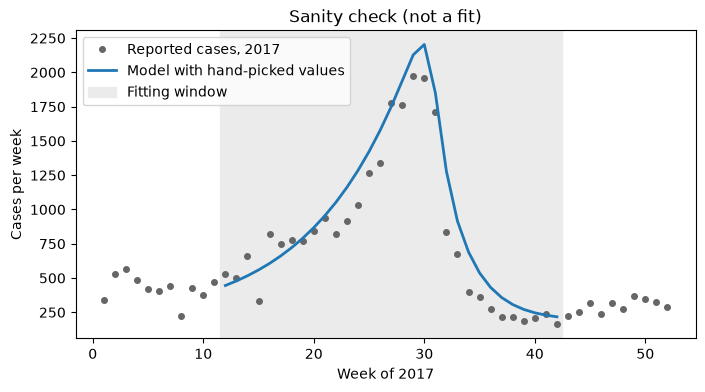

R0 before the drop = 1.11; model peak = 2203 cases in week 30


In [13]:
GUESS = {"beta": 1.20, "delta": 0.40, "tau": 31.5, "I0": 200.0, "bg": 190.0}
run = simulate(GUESS)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cases["week"], cases["cases"], "o", ms=4, color="0.4", label="Reported cases, 2017")
ax.plot(run["week"], run["expected_cases"], "-", lw=2, label="Model with hand-picked values")
ax.axvspan(FIRST_WEEK - 0.5, LAST_WEEK + 0.5, color="0.92", zorder=0, label="Fitting window")
ax.set_xlabel("Week of 2017"); ax.set_ylabel("Cases per week")
ax.set_title("Sanity check (not a fit)"); ax.legend()
plt.show()
print(f"R0 before the drop = {GUESS['beta'] / GAMMA:.2f}; "
      f"model peak = {run['expected_cases'].max():.0f} cases in week {run['week'][run['expected_cases'].argmax()]}")

## 4. Verification

### 4.1 Solver checks

1. **Conservation.** People only move between groups, so $S + I + R$ must equal $N$ at every step.
2. **Analytic result.** With constant $\beta$, dividing $dS/dt$ by $dR/dt$ gives $dS/dR = -(\beta/\gamma)\,S/N$. Integrating gives the exact relation $S(t) = S_0\,e^{-R_0 R(t)/N}$, which the solver must reproduce.
3. **Convergence order.** RK4's error should fall as $h^4$: a slope of about 4 on a log-log plot.
4. **Limiting cases.** With $R_0 < 1$ the number infected must only fall, and a 0% control cut must reproduce the baseline exactly.

In [14]:
# Check 1: conservation of S + I + R = N
drift = np.max(np.abs(run["S"] + run["I"] + run["R"] - N)) / N
assert drift < 1e-12, f"S+I+R drifted from N by {drift:.1e}"
print(f"PASS 1 (conservation): max |S+I+R-N|/N = {drift:.1e}")

PASS 1 (conservation): max |S+I+R-N|/N = 6.0e-16


In [15]:
# Check 2: analytic SIR relation S(t) = S0 * exp(-R0 * R(t) / N) for constant beta
CONST = {"beta": 2.0 * GAMMA, "delta": 0.0, "tau": 0.0, "I0": 50.0, "bg": 0.0}   # R0 = 2
r = simulate(CONST, first_week=0, last_week=40, steps_per_week=20)
S0 = N - CONST["I0"]
S_exact = S0 * np.exp(-(CONST["beta"] / GAMMA) * r["R"] / N)
rel_err = np.max(np.abs(r["S"] - S_exact) / S_exact)
assert rel_err < 1e-6, f"analytic check failed: max relative error {rel_err:.1e}"
print(f"PASS 2 (analytic relation): max relative error = {rel_err:.1e}")

PASS 2 (analytic relation): max relative error = 1.0e-09


PASS 3 (RK4 order): fitted slope = 4.03 (expected 4)


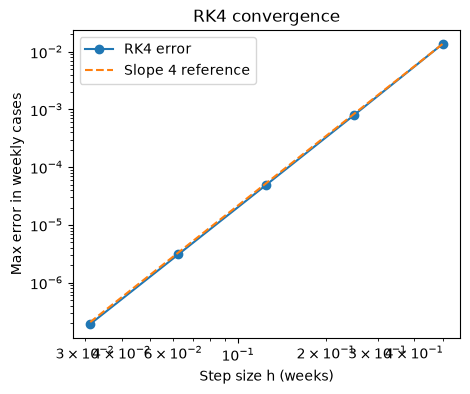

In [16]:
# Check 3: RK4 error falls as h^4 (compared with a very fine reference solution)
CTRL = {"cut": 0.2, "start": 25, "weeks": 6}          # include a control period, so the switches are tested too
steps = np.array([2, 4, 8, 16, 32])
h = 1 / steps
reference = simulate(GUESS, CTRL, steps_per_week=1024)["expected_cases"]
errors = np.array([np.max(np.abs(simulate(GUESS, CTRL, steps_per_week=s)["expected_cases"] - reference))
                   for s in steps])
slope = np.polyfit(np.log(h), np.log(errors), 1)[0]
assert 3.6 < slope < 4.4, f"expected a slope of about 4, got {slope:.2f}"
print(f"PASS 3 (RK4 order): fitted slope = {slope:.2f} (expected 4)")

fig, ax = plt.subplots(figsize=(5, 4))
ax.loglog(h, errors, "o-", label="RK4 error")
ax.loglog(h, errors[0] * (h / h[0]) ** 4, "--", label="Slope 4 reference")
ax.set_xlabel("Step size h (weeks)"); ax.set_ylabel("Max error in weekly cases")
ax.set_title("RK4 convergence"); ax.legend()
plt.show()

In [17]:
# Check 4: limiting cases
LOW = {"beta": 0.8 * GAMMA, "delta": 0.0, "tau": 0.0, "I0": 500.0, "bg": 0.0}     # R0 = 0.8 < 1
low = simulate(LOW)
assert np.all(np.diff(low["I"]) < 0), "with R0 < 1 the number infected should only fall"

no_cut = simulate(GUESS, {"cut": 0.0, "start": 25, "weeks": 6})["expected_cases"]
assert np.array_equal(no_cut, run["expected_cases"]), "a 0% cut must reproduce the baseline exactly"
print("PASS 4 (limiting cases): R0 < 1 dies out, and a 0% cut equals the baseline")

PASS 4 (limiting cases): R0 < 1 dies out, and a 0% cut equals the baseline


## 5. Experiments and results

[Parameter study or scenario comparison that answers your question. Report replications/seeds and confidence intervals, not single runs.]

In [8]:
# REPLACE: your parameter sweep or scenario comparison

## 6. Discussion and limitations

[What the results mean for the real-world question; the most important assumptions and their effect; what you would do next.]

**Web demo reference value:** with default settings the web demo should reproduce [value ± tolerance] from section [N].

## 7. References

[1] Epidemiology Unit, Ministry of Health, Sri Lanka, "Weekly Epidemiological Report." [Online]. Available: https://www.epid.gov.lk. Compiled in T. S. Talagala, *denguedatahub: A Tidy Format Datasets of Dengue by Country*, R package v4.1.2. [Online]. Available: https://github.com/thiyangt/denguedatahub

[2] L. B. Carrington and C. P. Simmons, "Human to mosquito transmission of dengue viruses," *Frontiers in Immunology*, vol. 5, art. no. 290, 2014, doi: 10.3389/fimmu.2014.00290.

[3] Department of Census and Statistics, Sri Lanka, "Census of Population and Housing 2024." [Online]. Available: https://www.statistics.gov.lk

[4] W. O. Kermack and A. G. McKendrick, "A contribution to the mathematical theory of epidemics," *Proceedings of the Royal Society A*, vol. 115, pp. 700–721, 1927, doi: 10.1098/rspa.1927.0118.